# Solutions to notebook 12: Polar coordinates: disks, drums and pipes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/12_polar_coordinates.ipynb)

Worked solutions to the exercises at the end of [notebook 12](../notebooks/12_polar_coordinates.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.linalg import eig, solve
from scipy.optimize import brentq
from scipy.special import jn_zeros, jv

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

# fourier_diff2_matrix(N) from notebook 2
def fourier_diff2_matrix(N):
    """Second-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D2 = np.full((N, N), -np.pi**2 / (3 * h**2) - 1 / 6)
    off = k != 0
    D2[off] = -0.5 * (-1.0) ** k[off] / np.sin(k[off] * h / 2) ** 2
    return D2

# barycentric_interpolate(values, x_eval) from notebook 4
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

# clenshaw_curtis(N) and cc_on(N, a, b) from notebook 10
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

def cc_on(N, a, b):
    """Clenshaw-Curtis nodes and weights mapped from [-1, 1] to [a, b]."""
    x, w = clenshaw_curtis(N)
    return a + (b - a) * (x + 1) / 2, w * (b - a) / 2

In [3]:
# functions from notebook 12
def radial_blocks(N):
    """Blocks of u_rr + u_r/r on the diameter grid (N odd), for rows at the interior points r > 0.

    Returns E1 (acting on values at r_i > 0), E2 (acting on their mirror images at -r_i),
    the radii r_1 > ... > r_n > 0, and the two wall columns (for r = +1 and r = -1).
    """
    if N % 2 == 0:
        raise ValueError("N must be odd, so that r = 0 is not a grid point")
    D, r = cheb(N)
    A = D @ D + np.diag(1 / r) @ D
    n = (N - 1) // 2
    pos = np.arange(1, n + 1)                 # indices of the interior points with r > 0
    neg = N - pos                             # indices of their mirror images, r_{N-i} = -r_i
    return A[np.ix_(pos, pos)], A[np.ix_(pos, neg)], r[pos], A[pos, 0], A[pos, N]

def disk_laplacian(N, M):
    """Laplacian on the unit disk for u = 0 at r = 1. N odd (Chebyshev, diameter), M even (Fourier).

    Unknowns U[i, j] = u(r_i, θ_j), flattened row by row. Returns L, r (the n = (N-1)/2 radii) and θ.
    """
    E1, E2, r, _, _ = radial_blocks(N)
    theta = 2 * np.pi * np.arange(M) / M
    I = np.eye(M)
    P = np.roll(I, M // 2, axis=1)            # (P g)_j = g_{j + M/2}: the value half a turn away
    L = np.kron(E1, I) + np.kron(E2, P) + np.kron(np.diag(1 / r**2), fourier_diff2_matrix(M))
    return L, r, theta

def radial_operator(N):
    """u'' + u'/r on the points r_1 > ... > r_n > 0 for even functions with u(1) = 0. Returns the matrix and r."""
    E1, E2, r, _, _ = radial_blocks(N)
    return E1 + E2, r

def on_diameter(values, wall=0.0):
    """Helper for these solutions: values at r_1 > ... > r_n > 0 of an even function, extended to all N + 1 points of the diameter."""
    return np.concatenate([[wall], values, values[::-1], [wall]])

## Exercise 1

**Why a drum has no pitch.** With `disk_laplacian(31, 24)` compute the first six distinct
frequencies $\omega = \sqrt\lambda$ of the drum and their ratios to the lowest one. Compare
with the ratios $1 : 2 : 3 : \dots$ of a string. Then find, by trial, the smallest odd $N$
(keeping $M = 24$) for which the first seventeen eigenvalues are all correct to $10^{-7}$.

The eigenvalues of $-L$ are $\lambda = \omega^2$. Sort them, take square roots, and pick out
the distinct ones: the modes with $m \ge 1$ come in pairs. The exact frequencies are the Bessel
zeros $j_{m,k}$. For the second part, loop over odd $N$ and compare the first seventeen sorted
eigenvalues with the sorted list of $j_{m,k}^2$, in which every zero with $m \ge 1$ appears
twice.

  m  k    ω computed     ω = j_mk     ratio to the lowest
  0  1    2.40482556   2.40482556         1.0000
  1  1    3.83170597   3.83170597         1.5933
  2  1    5.13562230   5.13562230         2.1355
  0  2    5.52007811   5.52007811         2.2954
  3  1    6.38016190   6.38016190         2.6531
  1  2    7.01558667   7.01558667         2.9173

   N   unknowns   largest error in the first 17 eigenvalues
  11      120            1.2e+00
  13      144            1.5e-01
  15      168            8.9e-03
  17      192            5.7e-04
  19      216            2.2e-05
  21      240            1.0e-06
  23      264            2.9e-08
  25      288            9.6e-10
  27      312            2.0e-11


  29      336            3.4e-12
  31      360            4.0e-12
smallest odd N with all seventeen correct to 1e-7: 23


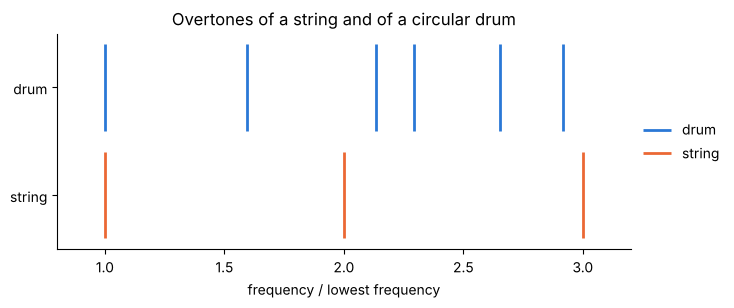

In [4]:
exact_list = sorted((zero**2, m, k + 1) for m in range(9) for k, zero in enumerate(jn_zeros(m, 4))
                    for copy in range(1 if m == 0 else 2))          # (λ, m, k), each m ≥ 1 listed twice
exact_17 = np.array([value for value, _, _ in exact_list[:17]])

def drum_eigenvalues(N, M=24, count=17):
    """The lowest eigenvalues λ of -∇² on the unit disk, sorted."""
    values = eig(-disk_laplacian(N, M)[0], right=False)
    return np.sort(values.real)[:count]

computed = drum_eigenvalues(31)
omega = np.sqrt(computed)
distinct = [0] + [i for i in range(1, 17) if omega[i] - omega[i - 1] > 1e-6]      # first member of each pair
omega_six = omega[distinct[:6]]
print("  m  k    ω computed     ω = j_mk     ratio to the lowest")
for index, w_drum in zip(distinct[:6], omega_six):
    value, m, k = exact_list[index]
    print(f"{m:3d} {k:2d} {w_drum:13.8f} {np.sqrt(value):12.8f} {w_drum / omega_six[0]:14.4f}")

print("\n   N   unknowns   largest error in the first 17 eigenvalues")
worst = {}
for N in range(11, 33, 2):
    worst[N] = np.abs(drum_eigenvalues(N) - exact_17).max()
    print(f"{N:4d} {(N - 1) // 2 * 24:8d} {worst[N]:18.1e}")
N_smallest = min(N for N in worst if worst[N] < 1e-7)
print(f"smallest odd N with all seventeen correct to 1e-7: {N_smallest}")

fig, ax = plt.subplots(figsize=(7.4, 2.8))
ax.vlines(omega_six / omega_six[0], 1.1, 1.9, color="#2a78d6", label="drum")
ax.vlines(np.arange(1, 4), 0.1, 0.9, color="#eb6834", label="string")
ax.set(xlabel="frequency / lowest frequency", yticks=[0.5, 1.5], yticklabels=["string", "drum"], xlim=(0.8, 3.2), ylim=(0, 2),
       title="Overtones of a string and of a circular drum")
ax.grid(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [5]:
# verify: the Bessel zeros from SciPy, the tabulated ratios, and the outcome of the search
assert np.abs(omega_six - [jn_zeros(0, 1)[0], jn_zeros(1, 1)[0], jn_zeros(2, 1)[0], jn_zeros(0, 2)[1], jn_zeros(3, 1)[0], jn_zeros(1, 2)[1]]).max() < 1e-9
assert np.abs(omega_six[1:] / omega_six[0] - [1.5933, 2.1355, 2.2954, 2.6531, 2.9173]).max() < 1e-4   # tabulated ratios of Bessel zeros
overtones = omega_six[1:] / omega_six[0]
assert np.abs(overtones - np.round(overtones)).min() > 0.08       # none of the overtones is harmonic
assert np.abs(drum_eigenvalues(21) - exact_17).argmax() == 14 and exact_list[14][1:] == (0, 3)     # the last to converge
assert worst[N_smallest] < 1e-7 < worst[N_smallest - 2] and all(worst[N] < 1e-7 for N in worst if N >= N_smallest)

**Answer.** The first six distinct frequencies are $\omega = 2.4048,\ 3.8317,\ 5.1356,\ 5.5201,\ 6.3802,\ 7.0156$,
the Bessel zeros $j_{0,1}, j_{1,1}, j_{2,1}, j_{0,2}, j_{3,1}, j_{1,2}$, in the ratios
$1 : 1.5933 : 2.1355 : 2.2954 : 2.6531 : 2.9173$. A string gives $1 : 2 : 3$. None of the drum's
overtones is a whole multiple of the lowest frequency, so the ear finds no common fundamental
and hears no definite pitch. With $M = 24$ the smallest odd $N$ that gives all seventeen
eigenvalues to $10^{-7}$ is $N = 23$ (264 unknowns, largest error $2.9\times10^{-8}$); $N = 21$
is ten times too coarse with $1.0\times10^{-6}$. Each increase of $N$ by 2 gains about a digit and a half,
and the mode that converges last is $(m, k) = (0, 3)$, the one with two nodal circles, which
oscillates most along the radius.

## Exercise 2

**Start-up of pipe flow.** A fluid at rest in a pipe is set in motion at $t = 0$ by a
constant pressure gradient. In units of $R^2/\nu$ for time the velocity obeys
$u_t = 1 + u_{rr} + u_r/r$ with $u(1, t) = 0$ and $u(r, 0) = 0$, and tends to
$(1 - r^2)/4$. Using `radial_operator(25)`, find the time at which the centreline velocity
reaches 99 % of its final value $\tfrac14$. Suggestions: write $u$ as the steady solution
minus a transient, expand the transient in the eigenvectors of the matrix, and find the
centreline value by evaluating the interpolant of the mirrored data at $r = 0$ with
`barycentric_interpolate` from notebook 4. Check your answer against the one-term estimate
$t \approx \ln(110.8)/j_{0,1}^2$.

Write $u = (1 - r^2)/4 - w$. The transient $w$ obeys $w_t = L_rw$ with $w(r, 0) = (1 - r^2)/4$.
If $-L_r$ has eigenvalues $\lambda_k$ and eigenvectors $\mathbf{v}_k$, then
$\mathbf{w}(t) = \sum_k c_k e^{-\lambda_kt}\mathbf{v}_k$, where the coefficients $c_k$ solve
$V\mathbf{c} = \mathbf{w}(0)$. This is exact in time: no time stepping and no stability limit.
The grid has no point at $r = 0$, so the centreline value comes from the interpolant along
the diameter. The time is then the root of $u(0, t) = 0.99/4$.

time to reach 99 % of the final centreline velocity: t = 0.814040   one-term estimate: 0.814037


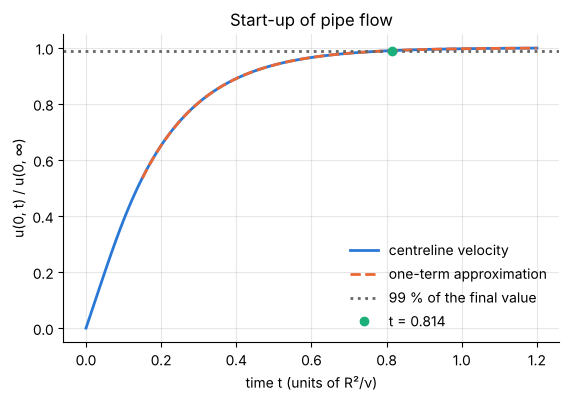

In [6]:
Lr, r = radial_operator(25)
rates, V = eig(-Lr)
rates, V = rates.real, V.real
steady = (1 - r**2) / 4
coefficients = solve(V, steady)                                    # expansion of the initial transient in the eigenvectors

def centreline_velocity(t):
    """u(0, t): steady solution minus transient, interpolated along the diameter to r = 0."""
    u = steady - V @ (coefficients * np.exp(-rates * t))
    return barycentric_interpolate(on_diameter(u), 0.0)[0]

t_99 = brentq(lambda t: centreline_velocity(t) - 0.99 / 4, 0.1, 3.0, xtol=1e-14)
j01 = jn_zeros(0, 1)[0]
t_one_term = np.log(110.8) / j01**2
print(f"time to reach 99 % of the final centreline velocity: t = {t_99:.6f}   one-term estimate: {t_one_term:.6f}")

times = np.linspace(0, 1.2, 121)
fig, ax = plt.subplots()
ax.plot(times, [4 * centreline_velocity(t) for t in times], label="centreline velocity")
ax.plot(times[15:], 1 - 4 * 2 / (j01**3 * jv(1, j01)) * np.exp(-j01**2 * times[15:]), "--", label="one-term approximation")
ax.axhline(0.99, color="0.4", ls=":", label="99 % of the final value")
ax.plot(t_99, 0.99, "o", color="#1baf7a", label=f"t = {t_99:.3f}")
ax.set(xlabel="time t (units of R²/ν)", ylabel="u(0, t) / u(0, ∞)", title="Start-up of pipe flow")
ax.legend(frameon=False, loc="lower right");

In [7]:
# verify: the classical Bessel series for the start-up flow, summed to 40 terms, and the one-term estimate
zeros = jn_zeros(0, 40)
series_centreline = lambda t: 0.25 - np.sum(2 * np.exp(-zeros**2 * t) / (zeros**3 * jv(1, zeros)))
t_series = brentq(lambda t: series_centreline(t) - 0.99 / 4, 0.1, 3.0, xtol=1e-14)
print(f"from the Bessel series: t = {t_series:.10f}    difference {abs(t_99 - t_series):.1e}")
assert abs(t_99 - t_series) < 1e-9
assert abs(t_99 - t_one_term) < 1e-3                               # the higher modes have died out by then
assert abs(centreline_velocity(0.0)) < 1e-12 and abs(centreline_velocity(50.0) - 0.25) < 1e-12
assert np.abs(np.sort(rates)[:3] - jn_zeros(0, 3) ** 2).max() < 1e-8

from the Bessel series: t = 0.8140403742    difference 2.3e-15


**Answer.** The centreline velocity reaches 99 % of its final value at $t = 0.8140\,R^2/\nu$,
in agreement with the Bessel series to rounding error and with the one-term estimate
$\ln(110.8)/j_{0,1}^2 = 0.8140$ to $3\times10^{-6}$: by that time only the slowest mode is left.
For water ($\nu = 10^{-6}$ m²/s) in a pipe of radius 1 cm this is 81 seconds, a reminder that
laminar flows take a long time to respond to a change in the pressure gradient.

## Exercise 3

**Flow in an annulus.** Between two concentric cylinders, $a \le r \le 1$ with $a = 0.5$,
there is no coordinate singularity, so an ordinary Chebyshev grid mapped to $[a, 1]$ will
do. Solve $u'' + u'/r = -1$ with $u(a) = u(1) = 0$ using $N = 16$ and compare with the exact
solution $u = \tfrac14\big[1 - r^2 - (1 - a^2)\ln r/\ln a\big]$. At what radius is the
velocity largest? Compare with the exact value $r^2 = (1 - a^2)/(2\ln(1/a))$.

Map the Chebyshev points to $r = a + (1 - a)(x + 1)/2$, which multiplies $D$ by $2/(1 - a)$.
Both ends are walls with $u = 0$, so the boundary rows and columns are deleted as in notebook
6. The maximum of the velocity is where $u' = 0$: differentiate the computed solution with $D$
and find the root of the interpolant of $u'$.

largest error against the exact solution: 1.1e-15
radius of the largest velocity: 0.735534255037   exact: 0.735534255037   largest velocity: 0.03165942


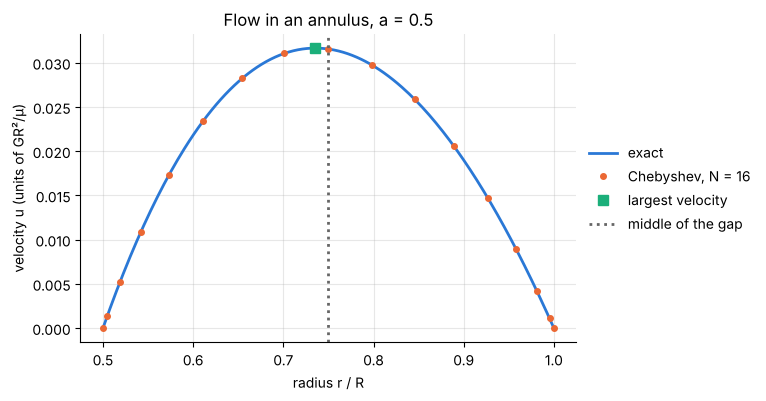

In [8]:
a, N = 0.5, 16
D, x = cheb(N)
r = a + (1 - a) * (x + 1) / 2                                      # index 0 is the outer wall r = 1, index N the inner wall r = a
D = 2 / (1 - a) * D
A = D @ D + np.diag(1 / r) @ D
u = np.zeros(N + 1)
u[1:N] = solve(A[1:N, 1:N], -np.ones(N - 1))
annulus_exact = lambda r: (1 - r**2 - (1 - a**2) * np.log(r) / np.log(a)) / 4
annulus_error = np.abs(u - annulus_exact(r)).max()

du = D @ u
x_max = brentq(lambda s: barycentric_interpolate(du, s)[0], -0.9, 0.9, xtol=1e-15)
r_max = a + (1 - a) * (x_max + 1) / 2
r_max_exact = np.sqrt((1 - a**2) / (2 * np.log(1 / a)))
u_max = barycentric_interpolate(u, x_max)[0]
print(f"largest error against the exact solution: {annulus_error:.1e}")
print(f"radius of the largest velocity: {r_max:.12f}   exact: {r_max_exact:.12f}   largest velocity: {u_max:.8f}")

r_fine = np.linspace(a, 1, 200)
fig, ax = plt.subplots()
ax.plot(r_fine, annulus_exact(r_fine), label="exact")
ax.plot(r, u, "o", ms=4, label="Chebyshev, N = 16")
ax.plot(r_max, u_max, "s", ms=7, color="#1baf7a", label="largest velocity")
ax.axvline((1 + a) / 2, color="0.4", ls=":", label="middle of the gap")
ax.set(xlabel="radius r / R", ylabel="velocity u (units of GR²/μ)", title="Flow in an annulus, a = 0.5")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [9]:
# verify: the exact solution, the exact position of the maximum, and the flow rate from the closed form
assert annulus_error < 1e-12
assert abs(r_max - r_max_exact) < 1e-11
r_q, w_q = cc_on(N, a, 1.0)                                        # the same points as r, with quadrature weights
flow_exact = np.pi / 8 * (1 - a**4 - (1 - a**2) ** 2 / np.log(1 / a))
print(f"flow rate: {2 * np.pi * w_q @ (u * r_q):.12f}   exact: {flow_exact:.12f}")
assert np.allclose(r_q, r) and abs(2 * np.pi * w_q @ (u * r_q) - flow_exact) < 1e-12

flow rate: 0.049473816620   exact: 0.049473816620


**Answer.** With $N = 16$ the largest error is $1\times10^{-15}$. The velocity is largest at
$r = 0.735534$, which agrees with the exact $\sqrt{(1 - a^2)/(2\ln(1/a))}$ to twelve digits,
and its value there is $0.031659\,GR^2/\mu$. The maximum lies slightly inside the middle of
the gap, $r = 0.75$: the inner wall has less area than the outer one, so it carries less of
the total drag, and the surface of zero shear stress sits closer to it.

## Exercise 4

**Slug flow.** Liquid metals have such high conductivity that the temperature field
develops while the velocity profile is still flat. Replace the weight $1 - \xi^2$ of the
Graetz problem by the constant $\tfrac12$ (uniform velocity with the same mean) and compute
the Nusselt number $\lambda_1^2/2$ with $N = 25$. Show that it equals $j_{0,1}^2 = 5.783$ and
explain why from 12.6.

Only the weight matrix changes: $W = \tfrac12I$ in place of $\operatorname{diag}(1 - \xi_i^2)$.
The generalized problem $-L_r\boldsymbol\phi = \lambda^2\,\tfrac12\boldsymbol\phi$ is then an
ordinary one, with $\lambda^2$ equal to twice an eigenvalue of $-L_r$.

In [10]:
Lr, xi = radial_operator(25)
squares = eig(-Lr, 0.5 * np.eye(len(xi)), right=False)
lam_slug = np.sqrt(np.sort(squares.real)[0])
Nu_slug = lam_slug**2 / 2
print(f"slug flow: λ1 = {lam_slug:.8f}   Nu = λ1²/2 = {Nu_slug:.8f}   j01² = {jn_zeros(0, 1)[0] ** 2:.8f}")

squares_graetz = eig(-Lr, np.diag(1 - xi**2), right=False)
Nu_parabolic = np.sort(squares_graetz.real)[0] / 2
print(f"parabolic profile (12.7): Nu = {Nu_parabolic:.6f}    ratio slug / parabolic: {Nu_slug / Nu_parabolic:.3f}")

slug flow: λ1 = 3.40093692   Nu = λ1²/2 = 5.78318596   j01² = 5.78318596
parabolic profile (12.7): Nu = 3.656793    ratio slug / parabolic: 1.581


In [11]:
# verify: the first zero of J0 from SciPy, and the Graetz value of 12.7 from the same code with the parabolic weight
assert abs(Nu_slug - jn_zeros(0, 1)[0] ** 2) < 1e-8 and round(Nu_slug, 3) == 5.783
assert abs(Nu_parabolic - 3.6568) < 1e-4

**Answer.** $\lambda_1 = 3.400937$ and $Nu = \lambda_1^2/2 = 5.783186 = j_{0,1}^2$. With the
constant weight $\tfrac12$ the Graetz equation is $\tfrac12\Theta_\zeta = \Theta_{\xi\xi} + \Theta_\xi/\xi$,
which is the cooling cylinder of 12.6 with $t = 2\zeta$: a slug of fluid moving at uniform
speed is a solid cylinder being cooled as it travels. Its decay rates are $j_{0,k}^2$ in $t$,
so $\lambda_k^2 = 2j_{0,k}^2$ and $Nu = \lambda_1^2/2 = j_{0,1}^2$. The value is 58 % higher than
the 3.657 of the parabolic profile, because the uniform profile brings more fluid past the
wall.

## Exercise 5

**Constant wall heat flux.** If the wall of the tube supplies a uniform heat flux instead,
the fully developed temperature $\theta = (T - T_w)\,k/(q''R)$ satisfies
$\theta'' + \theta'/\xi = 4(1 - \xi^2)$, $\theta(1) = 0$, and the Nusselt number is
$Nu = -2/\theta_b$ with the bulk temperature
$\theta_b = 4\int_0^1(1 - \xi^2)\,\theta\,\xi\,d\xi$. Solve for $\theta$ with
`radial_operator(15)`, evaluate the integral with Clenshaw-Curtis quadrature on $[0, 1]$
(notebook 10; interpolate the mirrored data to the quadrature points with
`barycentric_interpolate`), and confirm $Nu = 48/11 = 4.364$.

The right-hand side is known at the grid points and $\theta(1) = 0$, so one linear solve with
the folded operator gives $\theta$ at the seven radii $\xi_i > 0$. The quadrature points on
$[0, 1]$ are not those radii. The solution along the whole diameter is a polynomial through
the 16 points of the diameter grid (wall, values, mirrored values, wall), and
`barycentric_interpolate` evaluates it anywhere. The exact solution, found by integrating
twice, is $\theta = \xi^2 - \tfrac14\xi^4 - \tfrac34$, a polynomial of degree 4, so everything
here should be exact to rounding error: the integrand has degree 7 and Clenshaw-Curtis with
$N = 8$ integrates it exactly.

In [12]:
Lr, xi = radial_operator(15)
theta = solve(Lr, 4 * (1 - xi**2))
theta_exact = lambda s: s**2 - s**4 / 4 - 3 / 4

s, w = cc_on(8, 0.0, 1.0)                                          # quadrature points and weights on [0, 1]
theta_s = barycentric_interpolate(on_diameter(theta), s)           # θ at the quadrature points
theta_bulk = 4 * w @ ((1 - s**2) * theta_s * s)
Nu_flux = -2 / theta_bulk
print(f"largest error in θ at the grid points: {np.abs(theta - theta_exact(xi)).max():.1e}")
print(f"θ at the centre: {barycentric_interpolate(on_diameter(theta), 0.0)[0]:.12f}    bulk temperature θ_b = {theta_bulk:.12f}   (−11/24 = {-11 / 24:.12f})")
print(f"Nu = {Nu_flux:.12f}    48/11 = {48 / 11:.12f}")

largest error in θ at the grid points: 1.2e-15
θ at the centre: -0.750000000000    bulk temperature θ_b = -0.458333333333   (−11/24 = -0.458333333333)
Nu = 4.363636363636    48/11 = 4.363636363636


In [13]:
# verify: the exact polynomial solution, θ_b = −11/24 by hand, and the textbook Nusselt number
assert np.abs(theta - theta_exact(xi)).max() < 1e-12
assert np.abs(theta_s - theta_exact(s)).max() < 1e-12              # the interpolant between the grid points
assert abs(theta_bulk + 11 / 24) < 1e-12
assert abs(Nu_flux - 48 / 11) < 1e-11 and round(Nu_flux, 3) == 4.364

**Answer.** $\theta_b = -11/24 = -0.458333$ and $Nu = 4.363636 = 48/11$, to rounding error
with seven unknowns and nine quadrature points, because the solution is a polynomial of
degree 4. The same value came out of the quadrature in notebook 10, where the profile was
given. Here it is computed from the energy equation. A uniform wall flux gives a Nusselt
number 19 % higher than a uniform wall temperature (3.657).